# Team 6: floor-plan autoencoder — revision 3, integrated batch normalization

Chloe Hraibeh, Jeff El Khoury, Luca Obejdeanu — IAAC MaAI 2026/27

This is the third revision of the image-reconstruction notebook, **not** the supervised room-prediction model in `internal_layout_v3.ipynb`.

## What changed
- Batch normalization is explicitly part of the main convolutional architecture: hidden convolutions use **Conv → BatchNorm2d → ReLU**, and hidden decoder convolutions use **ConvTranspose → BatchNorm2d → ReLU**.
- The 128-number bottleneck and final sigmoid image output are not normalized.
- Setup A remains a dense reference; setups B and C use the integrated batch-normalization architecture by default.
- Section 3 retains a four-way ablation: no BN/default initialization, no BN/explicit initialization, BN/default initialization, and BN/explicit initialization.
- Initialization is a separate controlled choice, not automatically applied to the main models.
- Model selection uses validation retrieval, with validation MSE as a tie-breaker.
- New figures, weights and exports go to separate `*_bn_architecture` folders. Data cache paths are unchanged.

## Run instructions
Save this file beside the original notebook in `01_autoencoder/notebook/`. Select the same Python environment and run cells from the top. The main three-setup training, four-way comparison, cleaned-input training and atlas calculations may take several minutes.

All execution outputs have been cleared. Code syntax and architecture wiring were checked here, but **training, numerical inference and ONNX export have not been run here**. Recalculate results before filling in conclusions or deploying this revision. Existing server files still expect their original model version.

## Goal
Encode floor-plan images and retrieve five visually similar plans. The shifted/noisy-copy benchmark measures original recovery, not architectural usefulness.

| Section | Content |
|---|---|
| 0 | Environment and separate output folders |
| 1 | Data and image preparation |
| 2 | Dense reference and explicit batch-normalized ConvAE architecture |
| 3 | Validation comparison and four-way ablation |
| 4 | Retrieval, failure inspection and latent-space visualizations |
| 5 | Export a matching model, configuration and collection |
| 6 | Repeat with cleaned drawings |
| 7 | Record new conclusions |


# 0. Setup

In [2]:
# Only needed in a new environment: remove the "#" and run once.
%pip install torch torchvision scikit-learn matplotlib umap-learn onnx onnxscript onnxruntime pandas numpy

Note: you may need to restart the kernel to use updated packages.


In [3]:
import json
import time
import warnings
import zipfile
from pathlib import Path

#hide three harmless warnings that umap prints (progress bars, a future default, parallel jobs)
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="n_jobs value")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import umap

In [4]:
# --- Folders (relative paths: this notebook lives in 01_autoencoder/notebook/) ---
ROOT = Path("..")
DATA_DIR = ROOT / "data"            # ignored by git: the data is never committed
FIG_DIR = ROOT / "figures_bn_architecture"
MODEL_DIR = ROOT / "models_bn_architecture"         # uploaded to Hugging Face, not to GitHub
MODEL_APP_DIR = ROOT / "model_app_bn_architecture"  # what Tuesday's server needs
for folder in [DATA_DIR, FIG_DIR, MODEL_DIR, MODEL_APP_DIR / "examples"]:
    folder.mkdir(parents=True, exist_ok=True)

pd.set_option("display.float_format", "{:,.4f}".format)

RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)

# Fixed CPU device and seed improve reproducibility; exact results can vary across environments.
DEVICE = "cpu"
print(f"PyTorch {torch.__version__}, using device: {DEVICE}")


def save_fig(name):
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

PyTorch 2.15.0+cpu, using device: cpu


# 1. The data

### Dataset card
| | |
|---|---|
| Name | CubiCasa5K |
| Source | [Zenodo 2613548](https://zenodo.org/records/2613548) |
| Content | 5,000 floor-plan images, mostly of Finnish homes, with SVG annotations of walls, rooms, doors and windows. Official split: 4,200 train, 400 validation, 400 test |
| Licence | Dataset: [CC BY-NC 4.0](https://github.com/CubiCasa/CubiCasa5k/blob/master/LICENSE). Our code is MIT |
| Cite | Kalervo, A. et al. (2019), CubiCasa5K: A Dataset and an Improved Multi-Task Model for Floorplan Image Analysis, SCIA |
| We use | only the images (`F1_scaled.png`, the first floor of each home). An autoencoder needs no labels, so we don't use the annotations |

### Preprocessing, and why
1. Greyscale: the colour says almost nothing about the layout.
2. Invert: the plans are dark lines on white paper. After inverting, the walls are bright (1) and the background is dark (0), like the clothes in the class notebook. Otherwise most of the error would be about the empty white paper.
3. Pad to a square, then resize to 128 x 128 px. With the padding a long, narrow plan stays long and narrow instead of getting squashed.
4. Pixels between 0 and 1 (divided by 255).

The server on Tuesday has to do exactly the same steps, so they also go into the config file in section 5.

In [5]:
IMAGE_SIZE = 128


def preprocess_plan(image):
    # PIL image -> 128x128 numpy array, walls bright (1), background dark (0)
    grey = ImageOps.grayscale(image)
    inverted = ImageOps.invert(grey)
    side = max(inverted.size)
    square = Image.new("L", (side, side), 0)                     # black square = empty paper after inverting
    square.paste(inverted, ((side - inverted.width) // 2, (side - inverted.height) // 2))
    small = square.resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.LANCZOS)
    return np.asarray(small, dtype=np.uint8)

The download is one 5.5 GB zip. The notebook reads the plans straight from the zip, without unzipping it, and saves the small 128 px versions in one file, `cubicasa5k_128.npz` (27 MB). This only runs once. After that the notebook loads the small file in a second, and if you already have it in `data/` you don't need the zip at all.

In [6]:
ZIP_PATH = DATA_DIR / "cubicasa5k.zip"
NPZ_PATH = DATA_DIR / f"cubicasa5k_{IMAGE_SIZE}.npz"

if not NPZ_PATH.exists():
    # Download first if needed (5.5 GB):  https://zenodo.org/records/2613548/files/cubicasa5k.zip?download=1
    with zipfile.ZipFile(ZIP_PATH) as zf:
        names = set(zf.namelist())
        arrays, ids, splits = [], [], []
        for split in ["train", "val", "test"]:
            listing = [n for n in names if n.endswith(f"/{split}.txt")][0]
            folders = zf.read(listing).decode().split()
            for folder in folders:                                  # e.g. /high_quality_architectural/2003/
                image_name = next(n for n in (f"cubicasa5k{folder}F1_scaled.png", f"cubicasa5k{folder}F1_original.png")
                                  if n in names)
                with zf.open(image_name) as f:
                    arrays.append(preprocess_plan(Image.open(f)))
                ids.append(folder.strip("/"))
                splits.append(split)
            print(f"{split}: {splits.count(split)} plans")
    np.savez_compressed(NPZ_PATH, images=np.stack(arrays), ids=np.array(ids), splits=np.array(splits))
    print(f"saved {NPZ_PATH}")

### Split first
We use the official train, validation and test split of the dataset, and we fix it before anything else. The test plans are only used at the end, once, to score each setup. With the official split our numbers can also be compared with other work on CubiCasa5K.

In [7]:
data = np.load(NPZ_PATH)
images, plan_ids, plan_splits = data["images"], data["ids"], data["splits"]

# uint8 0-255 -> float 0-1, shape (N, 1, 128, 128): (plans, channels, height, width)
X_all = torch.from_numpy(images).float().div(255).unsqueeze(1)
X_train = X_all[plan_splits == "train"]
X_val = X_all[plan_splits == "val"]
X_test = X_all[plan_splits == "test"]
ids_test = plan_ids[plan_splits == "test"]
style_test = np.array([i.split("/")[0] for i in ids_test])   # drawing style: high_quality, high_quality_architectural or colorful

print("train", tuple(X_train.shape), "| validation", tuple(X_val.shape), "| test", tuple(X_test.shape))
print(f"share of bright (wall/line) pixels: {X_train.mean():.3f}")

train (4200, 1, 128, 128) | validation (400, 1, 128, 128) | test (400, 1, 128, 128)
share of bright (wall/line) pixels: 0.065


Figure saved to ..\figures_bn_architecture\01_samples.png


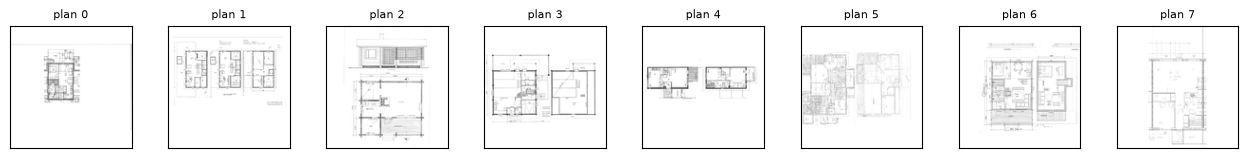

In [8]:
def show_images(rows, titles=None, row_labels=None, size=1.6):
    n_rows, n_cols = len(rows), len(rows[0])
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(size * n_cols, size * n_rows), squeeze=False)
    for r, batch in enumerate(rows):
        for c in range(n_cols):
            ax = axes[r, c]
            ax.imshow(1 - batch[c].squeeze().cpu(), cmap="gray", vmin=0, vmax=1)   # 1 - x: show as dark lines on white
            ax.set_xticks([]); ax.set_yticks([])
            if titles is not None and r == 0:
                ax.set_title(titles[c], fontsize=8)
        if row_labels is not None:
            axes[r, 0].set_ylabel(row_labels[r], fontsize=9)
    plt.tight_layout()


show_images([X_train[:8]], titles=[f"plan {i}" for i in range(8)])
save_fig("01_samples")
plt.show()

# 2. Three setups

A is the original dense reference with a 64-number code. B and C use the convolutional architecture below with **batch normalization integrated into the hidden convolution blocks**, with code sizes 32 and 128 respectively.

We retain the same official splits, BCE loss, 20 epochs, learning rate 0.001 and batch size 64. Reset the seed before constructing each model. Different architectures need not achieve identical results under one seed; small differences require further runs.

Batch normalization is applied to intermediate feature maps, not input pixel scaling. `model.train()` uses batch statistics and `model.eval()` uses running statistics. The existing helpers switch modes accordingly.


In [9]:
class DenseAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        n = IMAGE_SIZE * IMAGE_SIZE                     # 16,384 pixels
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(n, 256), nn.ReLU(),
            nn.Linear(256, latent_dim),                 # the code
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256), nn.ReLU(),
            nn.Linear(256, n), nn.Sigmoid(),
            nn.Unflatten(1, (1, IMAGE_SIZE, IMAGE_SIZE)),
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


class ConvAE(nn.Module):
    """Main architecture: normalization is enabled by default.

    Set batch_norm=False only for the controlled ablation.
    """
    def __init__(self, latent_dim=32, batch_norm=True):
        super().__init__()
        self.batch_norm = batch_norm
        # Identity preserves the same block layout for the no-BN control.
        def norm(channels):
            return nn.BatchNorm2d(channels) if batch_norm else nn.Identity()

        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, 3, stride=2, padding=1),
            norm(16), nn.ReLU(),                 # 128 -> 64
            nn.Conv2d(16, 32, 3, stride=2, padding=1),
            norm(32), nn.ReLU(),                 # 64 -> 32
            nn.Conv2d(32, 64, 3, stride=2, padding=1),
            norm(64), nn.ReLU(),                 # 32 -> 16
            nn.Conv2d(64, 64, 3, stride=2, padding=1),
            norm(64), nn.ReLU(),                 # 16 -> 8
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, latent_dim),   # unnormalized code
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64 * 8 * 8), nn.ReLU(),
            nn.Unflatten(1, (64, 8, 8)),
            nn.ConvTranspose2d(64, 64, 3, stride=2, padding=1, output_padding=1),
            norm(64), nn.ReLU(),                 # 8 -> 16
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1),
            norm(32), nn.ReLU(),                 # 16 -> 32
            nn.ConvTranspose2d(32, 16, 3, stride=2, padding=1, output_padding=1),
            norm(16), nn.ReLU(),                 # 32 -> 64
            nn.ConvTranspose2d(16, 1, 3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid(),                       # final image: no BatchNorm
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


# Check block counts and shapes without updating training running statistics.
check_model = ConvAE(latent_dim=128).eval()
assert sum(isinstance(m, nn.BatchNorm2d) for m in check_model.modules()) == 7
with torch.no_grad():
    check_input = torch.zeros(2, 1, IMAGE_SIZE, IMAGE_SIZE)
    assert check_model.encoder(check_input).shape == (2, 128)
    assert check_model(check_input).shape == check_input.shape
print(check_model)
print("Architecture checks passed: 4 encoder BN layers, 3 decoder BN layers.")
del check_model, check_input


ConvAE(
  (encoder): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (7): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): ReLU()
    (9): Conv2d(64, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (11): ReLU()
    (12): Flatten(start_dim=1, end_dim=-1)
    (13): Linear(in_features=4096, out_features=128, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=128, out_features=4096, bias=True)
   

The target remains the input image. We train with BCE and report MSE separately. Earlier MSE runs sometimes produced nearly blank images. BCE changes the optimization behavior but does not guarantee successful learning. Inverting pixels does not by itself solve background imbalance.

The training helper calls `model.train()` each epoch. Evaluation helpers call `model.eval()`, which is essential for the integrated BatchNorm layers.


In [10]:
def train_autoencoder(model, X_train, X_val, epochs=15, lr=1e-3, batch_size=64, verbose=True):
    torch.manual_seed(RANDOM_STATE)
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X_train), batch_size=batch_size, shuffle=True)
    history = []
    start = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        total = 0.0
        for (batch,) in loader:
            batch = batch.to(DEVICE)
            loss = nn.functional.binary_cross_entropy(model(batch), batch)   # target = input (BCE: see above)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(batch)
        val_mse = reconstruction_error(model, X_val).mean().item()
        history.append({"epoch": epoch, "train_loss": total / len(X_train), "val_mse": val_mse})
        if verbose:
            print(f"epoch {epoch:2d}  train loss {total / len(X_train):.4f}  validation MSE {val_mse:.4f}")
    seconds = time.time() - start
    print(f"trained in {seconds:.0f} s")
    return model, pd.DataFrame(history), seconds


@torch.no_grad()
def reconstruct(model, X, batch_size=200):
    model.eval()
    return torch.cat([model(X[i:i + batch_size].to(DEVICE)).cpu() for i in range(0, len(X), batch_size)])


@torch.no_grad()
def reconstruction_error(model, X, batch_size=200):
    # One number per plan: the mean squared difference between input and output
    model.eval()
    errors = []
    for i in range(0, len(X), batch_size):
        batch = X[i:i + batch_size].to(DEVICE)
        errors.append(((model(batch) - batch) ** 2).mean(dim=(1, 2, 3)).cpu())
    return torch.cat(errors)


@torch.no_grad()
def encode(model, X, batch_size=200):
    model.eval()
    return torch.cat([model.encoder(X[i:i + batch_size].to(DEVICE)).cpu() for i in range(0, len(X), batch_size)])


def n_params(model):
    return sum(p.numel() for p in model.parameters())

In [11]:
EPOCHS = 20
setups = {
    "A (dense, code 64)": lambda: DenseAE(latent_dim=64),
    "B (conv, code 32)": lambda: ConvAE(latent_dim=32),
    "C (conv, code 128)": lambda: ConvAE(latent_dim=128),
}
models, histories, times = {}, {}, {}
for name, make in setups.items():
    print(f"--- {name}")
    torch.manual_seed(RANDOM_STATE)
    models[name], histories[name], times[name] = train_autoencoder(make(), X_train, X_val, epochs=EPOCHS, verbose=False)

--- A (dense, code 64)
trained in 31 s
--- B (conv, code 32)
trained in 90 s
--- C (conv, code 128)
trained in 95 s


Figure saved to ..\figures_bn_architecture\02_training_curves.png


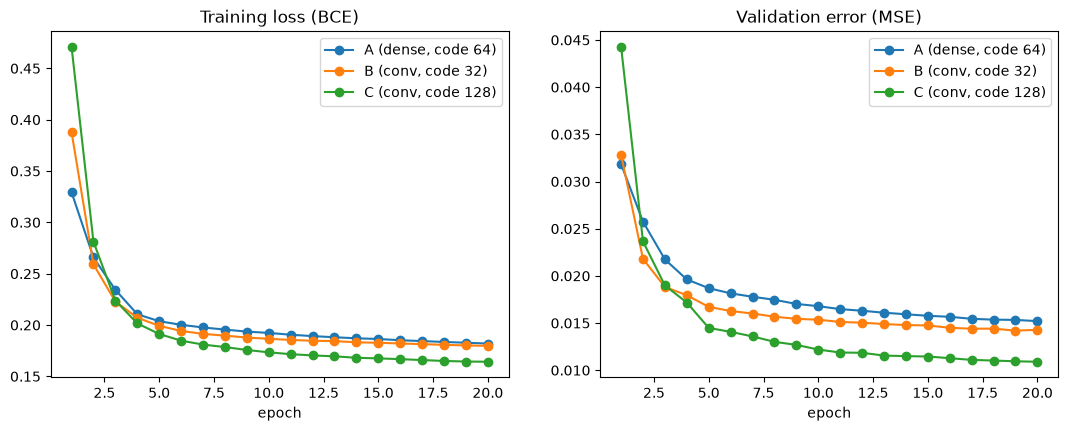

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for name, hist in histories.items():
    ax1.plot(hist["epoch"], hist["train_loss"], marker="o", label=name)
    ax2.plot(hist["epoch"], hist["val_mse"], marker="o", label=name)
ax1.set_title("Training loss (BCE)"); ax2.set_title("Validation error (MSE)")
for ax in (ax1, ax2):
    ax.set_xlabel("epoch"); ax.legend()
save_fig("02_training_curves")
plt.show()

### Training and validation results

All three setups improved over 20 epochs. Setup C, the convolutional
autoencoder with batch normalization and a 128-number code, achieved
the lowest final training BCE and validation MSE.

Setup C started with the highest error but overtook the other models.
Its validation MSE finished at approximately 0.0109, compared with
0.0143 for setup B and 0.0152 for the dense reference.

There was no sustained increase in validation error during this run.
These curves favour setup C for reconstruction, but validation
retrieval and reconstructed images must also be checked before
selecting the model for similarity search.

Inspect the fresh training and validation curves. Falling training loss with rising validation error may indicate overfitting. BCE and MSE use different scales.


# 3. Comparison table

Choose the main model using validation retrieval of shifted/noisy copies, with validation MSE as a tie-breaker. This measures original recovery, not different-home architectural relevance. Later cells report test metrics for frozen systems; do not use them to retune.


In [13]:
def perturb(X, shift=3, noise=0.05, seed=RANDOM_STATE):
    # A slightly changed copy of each plan: shifted a few pixels and with light noise
    g = torch.Generator().manual_seed(seed)
    shifted = torch.roll(X, shifts=(shift, -shift), dims=(2, 3))
    return (shifted + noise * torch.randn(shifted.shape, generator=g)).clamp(0, 1)


def retrieval_top1(model, X):
    codes = encode(model, X)
    query_codes = encode(model, perturb(X))
    nearest = torch.cdist(query_codes, codes).argmin(dim=1)
    return (nearest == torch.arange(len(X))).float().mean().item()


rows = []
for name, model in models.items():
    rows.append({
        "setup": name,
        "parameters": n_params(model),
        "train time (s)": round(times[name]),
        "validation MSE": histories[name]["val_mse"].iloc[-1],
        "retrieval top-1 (validation)": retrieval_top1(model, X_val),
    })
comparison = pd.DataFrame(rows)
comparison.to_csv(FIG_DIR / "03_comparison_table.csv", index=False)
comparison
# Freeze architecture choice using validation before test reporting.
best_name = comparison.sort_values(
    ["retrieval top-1 (validation)", "validation MSE"], ascending=[False, True]
).iloc[0]["setup"]
best = models[best_name]
print("Validation-selected main model:", best_name)


Validation-selected main model: C (conv, code 128)


Figure saved to ..\figures_bn_architecture\03_reconstructions.png


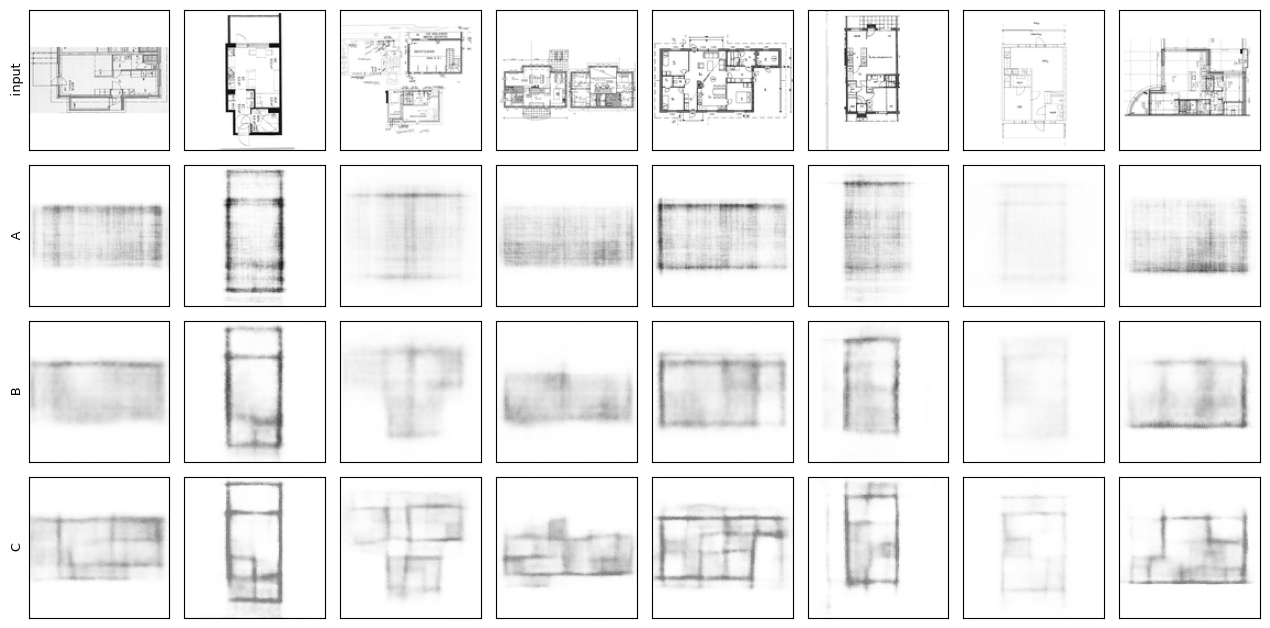

In [14]:
sample = X_val[:8]
show_images([sample] + [reconstruct(m, sample) for m in models.values()],
            row_labels=["input"] + [n.split(" (")[0] for n in models])
save_fig("03_reconstructions")
plt.show()

### Visual comparison of the three setups

Each column shows the same validation image reconstructed by setups
A, B and C.

The dense model A produces coarse shapes with grid-like artifacts.
Convolutional model B captures broad outlines but loses many internal
divisions. Model C, with batch normalization and a 128-number code,
preserves more internal structure in several displayed examples.

These observations support C's lower validation reconstruction MSE.
However, fine details remain blurred or missing, and reconstructed
partitions do not always match the input.

This figure compares complete setups; it does not isolate the effect
of batch normalization. The separate four-way experiment addresses
that question.

### Main comparison — complete after running

Record the validation-selected setup, parameters and validation scores from the current table. Old no-BN results do not describe these retrained architectures.


### Is the autoencoder worth it?
A fair question before keeping a neural network: would something simpler find the plans just as well? We run the same retrieval test with two simpler ways of comparing plans:
- the raw pixels: the 16,384 numbers of the image, compared directly;
- PCA with 128 components (Day 3), the same length as our code, fitted on the training plans.

PCA keeps 58% of the variance of the pixels
Figure saved to ..\figures_bn_architecture\05_baselines.png


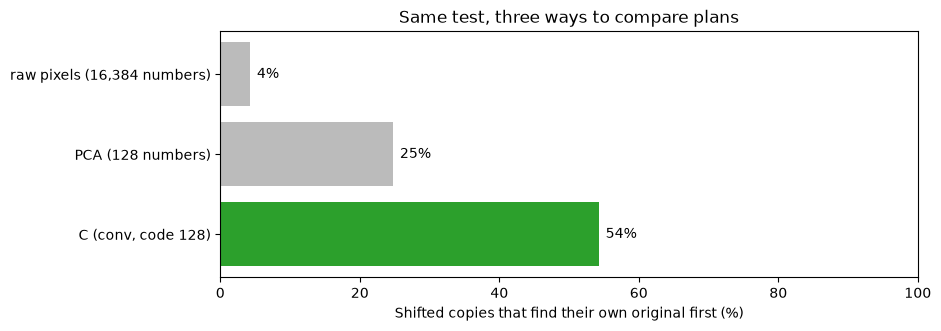

,method,retrieval top-1 (test)
0,"raw pixels (16,384 numbers)",0.0425
1,PCA (128 numbers),0.2475
2,"C (conv, code 128)",0.5425


In [15]:
#the same shifted copies, compared in two simpler ways: the raw pixels, and PCA with as many numbers as our code
from sklearn.decomposition import PCA


def retrieval_from_codes(codes, query_codes):
    #share of shifted copies whose closest code is the code of their own original
    nearest = torch.cdist(query_codes, codes).argmin(dim=1)
    return (nearest == torch.arange(len(codes))).float().mean().item()


X_test_shifted = perturb(X_test)
pixel_score = retrieval_from_codes(X_test.flatten(1), X_test_shifted.flatten(1))

pca = PCA(n_components=int(best.encoder[-1].out_features), random_state=RANDOM_STATE)
pca.fit(X_train.flatten(1).numpy())
pca_codes = torch.from_numpy(pca.transform(X_test.flatten(1).numpy()))
pca_queries = torch.from_numpy(pca.transform(X_test_shifted.flatten(1).numpy()))
pca_score = retrieval_from_codes(pca_codes, pca_queries)
print(f"PCA keeps {pca.explained_variance_ratio_.sum():.0%} of the variance of the pixels")

ae_score = retrieval_top1(best, X_test)
baselines = pd.DataFrame({"method": ["raw pixels (16,384 numbers)", f"PCA ({pca.n_components_} numbers)", best_name],
                          "retrieval top-1 (test)": [pixel_score, pca_score, ae_score]})

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(baselines["method"], baselines["retrieval top-1 (test)"] * 100, color=["#bbbbbb", "#bbbbbb", "#2ca02c"])
for i, value in enumerate(baselines["retrieval top-1 (test)"]):
    ax.text(value * 100 + 1, i, f"{value:.0%}", va="center")
ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.set_xlabel("Shifted copies that find their own original first (%)")
ax.set_title("Same test, three ways to compare plans")
save_fig("05_baselines")
plt.show()
baselines

### Retrieval compared with simple baselines

The batch-normalized convolutional model achieved 54.25% top-1
original recovery on shifted and noisy test images. It outperformed
raw-pixel comparison (4.25%) and PCA with 128 components (24.75%).

However, this is below the earlier notebook's recorded 69% result
without batch normalization. Improved reconstruction therefore did
not translate into improved retrieval in these recorded runs.

This benchmark measures recovery of the same plan among 400 test
images. It does not measure architectural relevance between
different homes. The separate four-way validation experiment
provides a more controlled comparison of normalization and
initialization.


### And the reconstruction error?
On their own the MSE values (0.0131 for C) are hard to read. Two dumb ways of "rebuilding" a plan give them a scale: a blank page, which is what the first MSE runs drew, and the average plan of the training set.

In [16]:
#two dumb reconstructions: a blank page (0 everywhere after inverting) and the average training plan
blank_mse = (X_test ** 2).mean().item()
average_plan = X_train.mean(dim=0, keepdim=True)
average_mse = ((X_test - average_plan) ** 2).mean().item()
c_mse = reconstruction_error(best, X_test).mean().item()

print(f"Selected model is {1 - c_mse / blank_mse:.0%} below the blank page and {1 - c_mse / average_mse:.0%} below the average plan")
pd.DataFrame({"reconstruction": ["blank page", "average training plan", best_name],
              "test MSE": [blank_mse, average_mse, c_mse]})

Selected model is 61% below the blank page and 51% below the average plan


,reconstruction,test MSE
0,blank page,0.0300
1,average training plan,0.0243
2,"C (conv, code 128)",0.0118


### Reconstruction compared with fixed-image baselines

The selected batch-normalized model achieved a test MSE of 0.0118.
This is approximately 61% lower than returning a blank page and
51% lower than returning the average training image.

The model therefore reconstructs information specific to each input
rather than simply returning a fixed image.

Compared with the earlier notebook's recorded test MSE of 0.0131,
reconstruction error decreased by approximately 10%. However,
original-recovery retrieval fell from 69% to 54.25% across these
recorded runs.

Better pixel reconstruction therefore did not translate into better
similarity retrieval. These metrics do not directly measure
architectural relevance.


### Testing batch normalization and weight initialization

We compare four versions of the convolutional autoencoder:

1. Original model.
2. Explicit weight initialization.
3. Batch normalization.
4. Both changes.

All versions use a code size of 128, the same data split, BCE loss,
learning rate, batch size and 20 training epochs.

We compare validation reconstruction error, visual reconstructions,
and validation retrieval before choosing a model.
The control passes `batch_norm=False`; the normalized versions pass `batch_norm=True` to the SAME explicit main architecture. Main setups B/C use BN by default.


In [17]:
# The architecture is defined directly in ConvAE above; no subclass insertion is needed.
# This cell confirms the two ablation settings.
print("BN enabled:", ConvAE(latent_dim=128, batch_norm=True).batch_norm)
print("BN disabled:", ConvAE(latent_dim=128, batch_norm=False).batch_norm)


BN enabled: True
BN disabled: False


In [18]:
def initialize_autoencoder(model):
    for layer in model.modules():

        # Hidden layers use ReLU:
        # choose Kaiming initialization.
        if isinstance(
            layer,
            (nn.Conv2d, nn.ConvTranspose2d, nn.Linear)
        ):
            nn.init.kaiming_normal_(
                layer.weight,
                mode="fan_in",
                nonlinearity="relu"
            )

            if layer.bias is not None:
                nn.init.zeros_(layer.bias)

        # Start batch normalization with scale 1 and offset 0.
        elif isinstance(layer, nn.BatchNorm2d):
            nn.init.ones_(layer.weight)
            nn.init.zeros_(layer.bias)

    # These two layers are not followed by ReLU:
    # use Xavier initialization instead.
    nn.init.xavier_uniform_(model.encoder[-1].weight)
    nn.init.xavier_uniform_(model.decoder[-2].weight)

In [19]:
experiment_settings = {
    "Original": (False, False),
    "Initialization only": (False, True),
    "Batch normalization only": (True, False),
    "Both": (True, True),
}

experiment_models = {}
experiment_histories = {}
experiment_times = {}

for name, (use_bn, use_initialization) in experiment_settings.items():
    print(f"\n--- {name} ---")

    # Reset the seed before creating each model.
    torch.manual_seed(RANDOM_STATE)

    candidate = ConvAE(latent_dim=128, batch_norm=use_bn)

    # Apply initialization once, before training.
    if use_initialization:
        initialize_autoencoder(candidate)

    trained, history, seconds = train_autoencoder(
        candidate,
        X_train,
        X_val,
        epochs=20,
        lr=0.001,
        batch_size=64,
        verbose=True
    )

    experiment_models[name] = trained
    experiment_histories[name] = history
    experiment_times[name] = seconds


--- Original ---
epoch  1  train loss 0.3291  validation MSE 0.0226
epoch  2  train loss 0.2265  validation MSE 0.0218
epoch  3  train loss 0.2208  validation MSE 0.0204
epoch  4  train loss 0.2082  validation MSE 0.0189
epoch  5  train loss 0.2007  validation MSE 0.0179
epoch  6  train loss 0.1968  validation MSE 0.0174
epoch  7  train loss 0.1932  validation MSE 0.0167
epoch  8  train loss 0.1904  validation MSE 0.0162
epoch  9  train loss 0.1874  validation MSE 0.0155
epoch 10  train loss 0.1850  validation MSE 0.0151
epoch 11  train loss 0.1826  validation MSE 0.0147
epoch 12  train loss 0.1803  validation MSE 0.0142
epoch 13  train loss 0.1784  validation MSE 0.0138
epoch 14  train loss 0.1769  validation MSE 0.0136
epoch 15  train loss 0.1757  validation MSE 0.0134
epoch 16  train loss 0.1744  validation MSE 0.0131
epoch 17  train loss 0.1734  validation MSE 0.0129
epoch 18  train loss 0.1726  validation MSE 0.0128
epoch 19  train loss 0.1716  validation MSE 0.0126
epoch 20  tra

Figure saved to ..\figures_bn_architecture\batchnorm_initialization_training.png


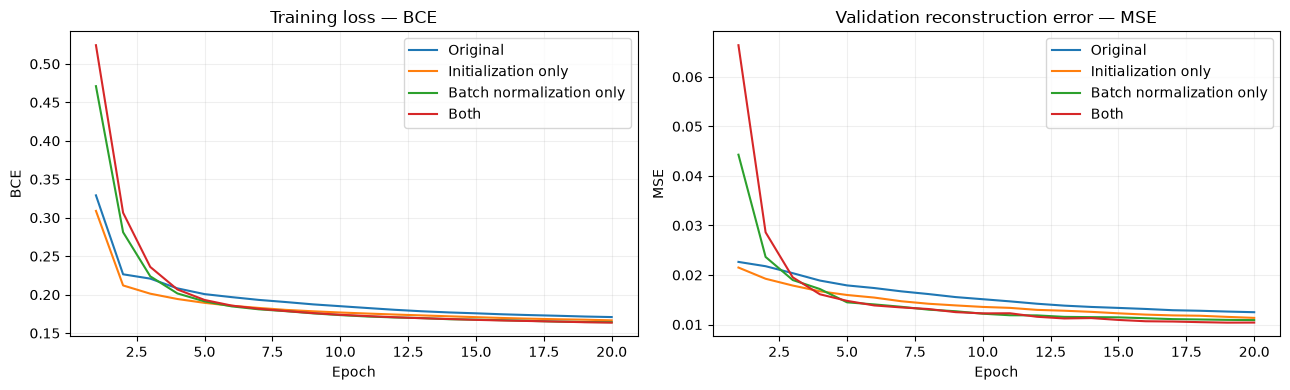

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for name, history in experiment_histories.items():
    axes[0].plot(
        history["epoch"],
        history["train_loss"],
        label=name
    )

    axes[1].plot(
        history["epoch"],
        history["val_mse"],
        label=name
    )

axes[0].set_title("Training loss — BCE")
axes[1].set_title("Validation reconstruction error — MSE")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.2)

axes[0].set_ylabel("BCE")
axes[1].set_ylabel("MSE")

plt.tight_layout()
save_fig("batchnorm_initialization_training")
plt.show()

### Effect of normalization and initialization

All four configurations improved over 20 epochs.

Explicit initialization produced lower validation error than the
original model early in training. The batch-normalized models
started with higher errors but improved rapidly.

Combining batch normalization and initialization achieved the
lowest final validation MSE: 0.0104 versus 0.0125 for the original,
approximately a 17% reduction in this single-seed run.

Validation error showed no sustained upward trend during training.
The left panel measures training BCE and the right panel validation
MSE; their numerical scales are not directly comparable.

This establishes a reconstruction improvement. Retrieval performance
must be assessed separately before selecting the search model.

### Reading the ablation curves

Left: BCE training loss. Right: validation reconstruction MSE. Compare models within each panel and inspect the final values. The earlier 17% improvement is historical, not a result of this file.


Figure saved to ..\figures_bn_architecture\batchnorm_initialization_reconstructions.png


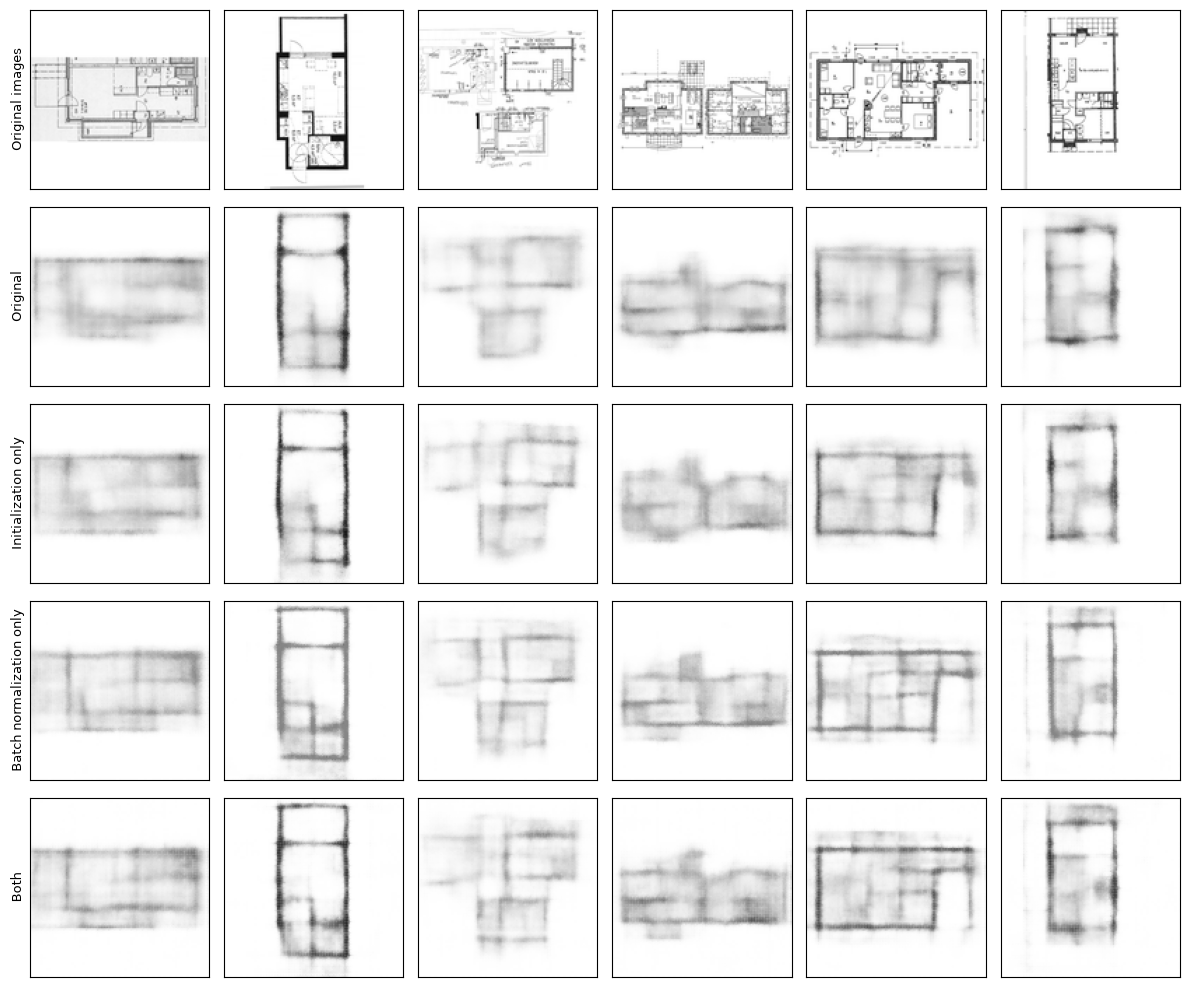

In [21]:
sample = X_val[:6]

image_rows = [sample]
row_labels = ["Original images"]

for name, model in experiment_models.items():
    image_rows.append(
        reconstruct(model, sample)
    )
    row_labels.append(name)

show_images(
    image_rows,
    row_labels=row_labels,
    size=2
)

save_fig("batchnorm_initialization_reconstructions")
plt.show()

### Visual effect of batch normalization and initialization

Each column compares the same validation plan across four settings.

The original model captures broad outlines but produces diffuse
internal structure. Initialization strengthens some boundaries.
Batch normalization, alone or combined with initialization, makes
several internal divisions more distinct.

The combined model achieves the lowest overall validation MSE,
but it is not visually superior in every displayed example.
Doors, furniture, text and thin walls remain poorly reconstructed,
and some predicted partitions differ from the originals.

These examples support a reconstruction improvement, but do not
establish better similarity retrieval.

In [22]:
experiment_rows = []

for name, model in experiment_models.items():
    experiment_rows.append({
        "model": name,
        "validation_MSE": reconstruction_error(
            model, X_val
        ).mean().item(),
        "validation_retrieval_top1": retrieval_top1(
            model, X_val
        ),
        "training_seconds": experiment_times[name]
    })

experiment_comparison = pd.DataFrame(experiment_rows)

display(experiment_comparison)

experiment_comparison.to_csv(
    FIG_DIR / "batchnorm_initialization_comparison.csv",
    index=False
)

,model,validation_MSE,validation_retrieval_top1,training_seconds
0,Original,0.0125,0.7375,80.3956
1,Initialization only,0.0113,0.3300,90.2778
2,Batch normalization only,0.0109,0.4550,139.1740
3,Both,0.0104,0.6550,182.2578


### Conclusion of the controlled comparison

Combining batch normalization and explicit initialization reduced
validation reconstruction MSE from 0.0125 to 0.0104, approximately 17%.

However, the original model without batch normalization achieved
the highest validation retrieval: 73.75%, compared with 65.50%
for the combined model.

The model trained to reconstruct pixels more accurately did not
necessarily produce codes better suited to Euclidean retrieval.
This benchmark measures recovery of shifted and noisy copies,
not architectural relevance between different homes.

For similarity search, the no-BN control is the strongest candidate
among these four configurations in this single-seed experiment.

# 4. Similarity search

Use the main validation-selected model. Display five nearest plans from the full 5,000-plan collection, excluding the query. This demonstration is distinct from the 400-plan same-original benchmark.


Using validation-selected main model: C (conv, code 128)
collection codes: (5000, 128)
query 0: distances 21.50-24.24
query 50: distances 30.82-32.40
query 120: distances 42.12-44.21
query 250: distances 23.11-26.22
for comparison, the median distance between two random plans is 52.97
Figure saved to ..\figures_bn_architecture\04_similarity_search.png


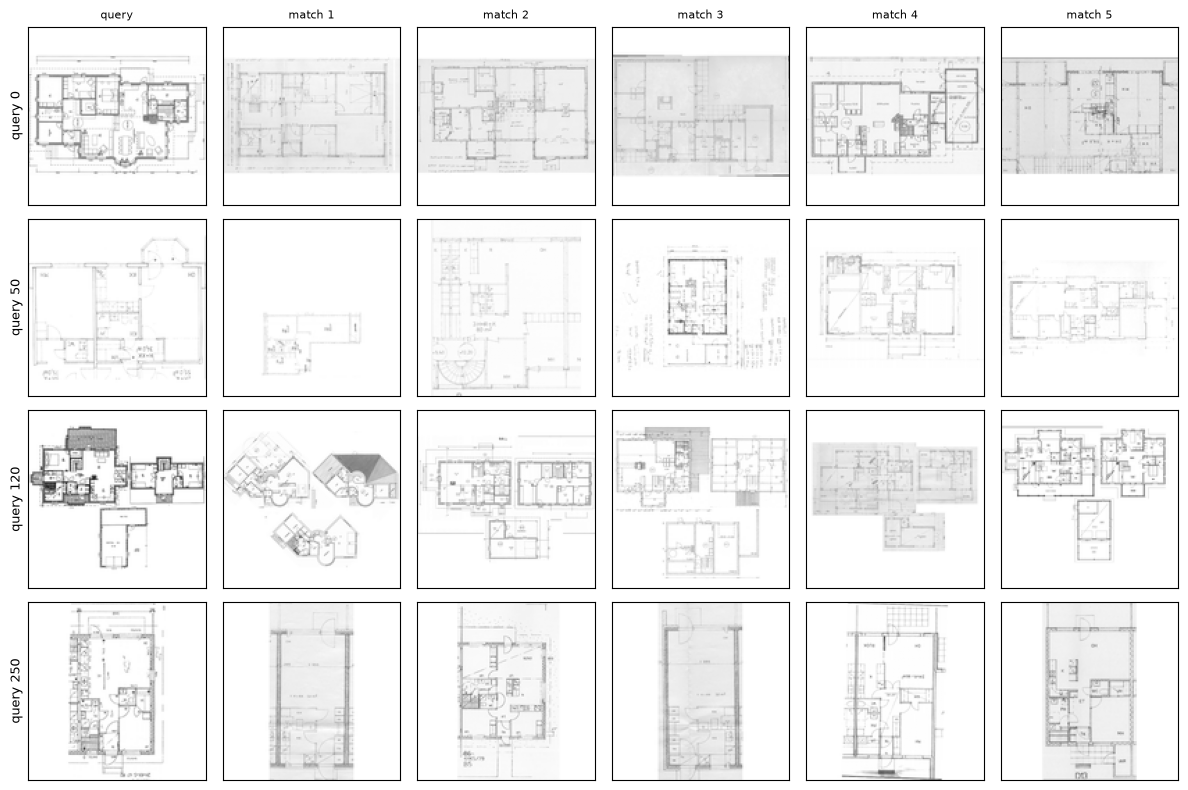

In [23]:
# The main model was selected using validation in section 3.
# The ablation is diagnostic; it does not silently replace the exported model.
print("Using validation-selected main model:", best_name)

codes_all = encode(best, X_all)          # one code per plan, for the whole collection
codes_test = encode(best, X_test)
print("collection codes:", tuple(codes_all.shape))


def most_similar(query_code, codes, k=5, exclude=None):
    distances = torch.cdist(query_code.unsqueeze(0), codes).squeeze(0)
    if exclude is not None:
        distances[exclude] = float("inf")       # do not return the query plan itself
    best_k = distances.topk(k, largest=False)
    return best_k.indices, best_k.values


test_positions = np.where(plan_splits == "test")[0]
rows, labels = [], []
for q in [0, 50, 120, 250]:
    query_index = test_positions[q]
    idx, dists = most_similar(codes_all[query_index], codes_all, exclude=query_index)
    rows.append(torch.cat([X_all[query_index:query_index + 1], X_all[idx]]))
    labels.append(f"query {q}")
    print(f"query {q}: distances {dists.min():.2f}-{dists.max():.2f}")
typical = torch.cdist(codes_test[:200], codes_test[:200]).median()
print(f"for comparison, the median distance between two random plans is {typical:.2f}")

show_images(rows, row_labels=labels, titles=["query"] + [f"match {i}" for i in range(1, 6)], size=2.0)
save_fig("04_similarity_search")
plt.show()

### Interpretation of similarity-search examples

The batch-normalized model retrieves plans with broadly similar
proportions and drawing composition. Wide and narrow queries
often return similarly proportioned drawings, while a query
containing several drawings retrieves other multi-part sheets.

However, internal room arrangements differ, and some matches
are not convincing architectural precedents. Drawing appearance
and placement on the page may still influence the codes.

The collection contains 5,000 plans represented by 128-number
codes. The displayed nearest-neighbour distances are below the
reference median distance, but this does not establish
architectural relevance.

These examples use the main batch-normalized model C, not
the no-BN control from the four-way comparison.

Figure saved to ..\figures_bn_architecture\04_latent_umap.png


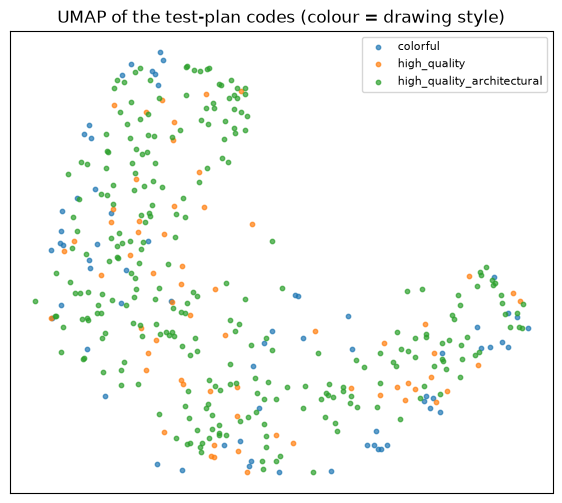

In [24]:
# The latent space in 2D (UMAP, as on Day 3). Colours = drawing style, which the model never saw.
embedding = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=RANDOM_STATE).fit_transform(codes_test.numpy())
fig, ax = plt.subplots(figsize=(7, 6))
for style in np.unique(style_test):
    mask = style_test == style
    ax.scatter(embedding[mask, 0], embedding[mask, 1], s=10, alpha=0.7, label=style)
ax.set_title("UMAP of the test-plan codes (colour = drawing style)")
ax.set_xticks([]); ax.set_yticks([]); ax.legend(fontsize=8)
save_fig("04_latent_umap")
plt.show()

### Interpretation of the UMAP map

UMAP projects the 128-dimensional test-plan codes into two dimensions.
Each point represents a plan, coloured by its CubiCasa5K subset.

The three colours are interspersed, without clearly separated groups
corresponding to the dataset subsets. This suggests that subset
membership alone does not explain the visible organisation.

However, colour mixing does not prove that the codes ignore drawing
style or capture meaningful architectural layouts. The subsets are
only coarse proxies for drawing appearance.

The curved shape and global distances should not be given a direct
architectural interpretation. The actual search compares codes in
the full 128-dimensional space.


### Where does search fail?

Compute failures and group original-recovery results by average image intensity and dataset subset. The group differences mix contrast and density; they do not directly measure scan quality.


Figure saved to ..\figures_bn_architecture\06_failures_by_ink.png


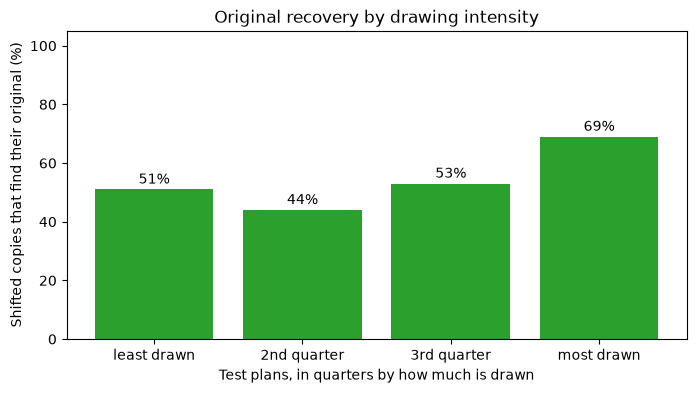

share of line pixels: 0.076 in the plans it finds, 0.062 in the ones it misses


,plans,retrieval top-1
colorful,67,0.5672
high_quality,63,0.2222
high_quality_architectural,270,0.6111


In [38]:
#for every test plan: does its shifted copy find it? Then by how much is drawn, and by subset
found = (torch.cdist(encode(best, X_test_shifted), codes_test).argmin(dim=1) == torch.arange(len(X_test))).numpy()
ink = X_test.mean(dim=(1, 2, 3)).numpy()
ink_quarter = pd.qcut(ink, 4, labels=["least drawn", "2nd quarter", "3rd quarter", "most drawn"])

by_ink = pd.Series(found).groupby(ink_quarter, observed=True).mean()
by_subset = pd.DataFrame({"plans": pd.Series(style_test).value_counts().sort_index(),
                          "retrieval top-1": pd.Series(found).groupby(style_test).mean()})

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_ink.index.astype(str), by_ink.values * 100, color="#2ca02c")
for i, value in enumerate(by_ink.values):
    ax.text(i, value * 100 + 2, f"{value:.0%}", ha="center")
ax.set_ylim(0, 105)
ax.set_ylabel("Shifted copies that find their original (%)")
ax.set_xlabel("Test plans, in quarters by how much is drawn")
ax.set_title("Original recovery by drawing intensity")
save_fig("06_failures_by_ink")
plt.show()

print(f"share of line pixels: {ink[found].mean():.3f} in the plans it finds, {ink[~found].mean():.3f} in the ones it misses")
by_subset

### Failure analysis by drawing intensity and dataset subset

Original recovery was highest in the most-drawn quarter (69%).
The other quarters scored 51%, 44% and 53%, so performance did
not increase consistently with drawing intensity.

Recovered plans had higher average inverted pixel intensity
than missed plans: 0.076 versus 0.062. This measure combines
drawing density and contrast; it does not isolate scan quality.

Results also varied across dataset subsets: 56.7% for colorful,
22.2% for high_quality and 61.1% for high_quality_architectural.
These differences require inspection of the failed examples
before attributing them to a particular cause.

Overall recovery was 54.25%. These results describe recovery
of shifted and noisy copies, not architectural relevance.

### The plans it misses
Six of the test plans whose shifted copy doesn't find them, with what the search returned instead.

Figure saved to ..\figures_bn_architecture\07_failure_gallery.png


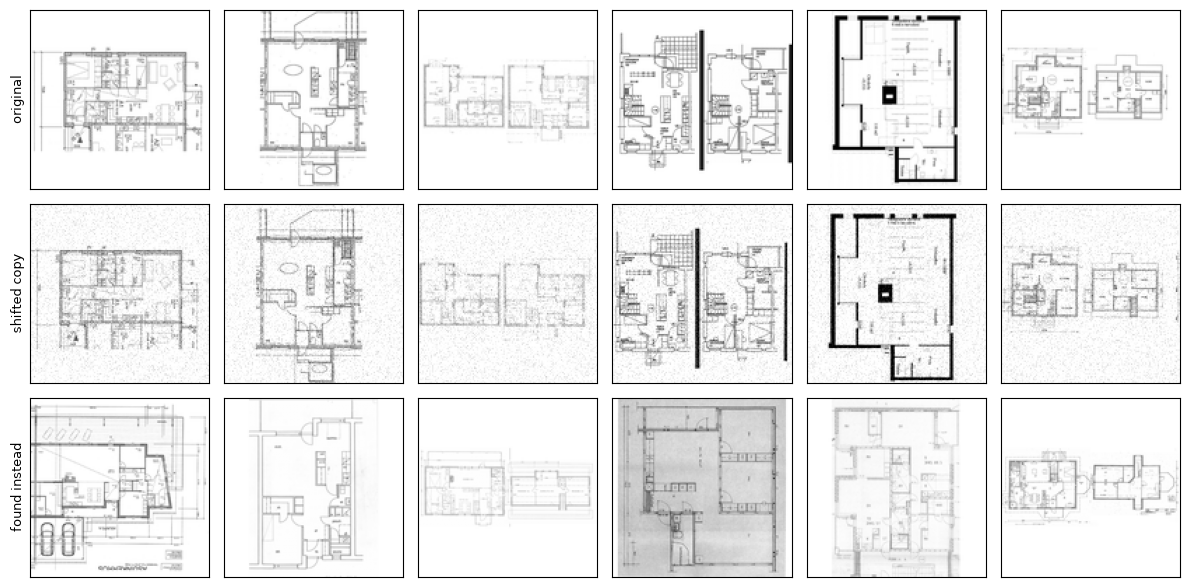

In [26]:
#the first six misses: the original, the shifted copy we searched with, and the plan the search returned instead
missed = np.where(~found)[0][:6]
found_instead = torch.cdist(encode(best, X_test_shifted[missed]), codes_test).argmin(dim=1)
show_images([X_test[missed], X_test_shifted[missed], X_test[found_instead]],
            row_labels=["original", "shifted copy", "found instead"], size=2.0)
save_fig("07_failure_gallery")
plt.show()

### Inspection of retrieval failures

These are the first six failed queries, not a random sample of
all failures. Each column shows the original, its shifted and
noisy copy, and the different plan returned first.

Failures occur on both faint and bold drawings. Some returned
plans share broad proportions or multi-part composition with
the query, while their internal arrangements differ.

The examples show that the encoder is not fully robust to the
tested shift and noise. They do not isolate the contribution of
each disturbance or establish that every incorrect match is a
useful architectural precedent.

The benchmark counts only recovery of the exact original as
success.

### An atlas of the 5,000 plans
To see how the model organises all the plans at once, we put the 5,000 codes on a 2D map with UMAP and draw the plans themselves instead of dots. The map is cut into a grid, and every cell shows the plan closest to its centre. Plans that are neighbours on the map have close codes, so they are the ones the app would show together.

Figure saved to ..\figures_bn_architecture\08_plan_atlas.png


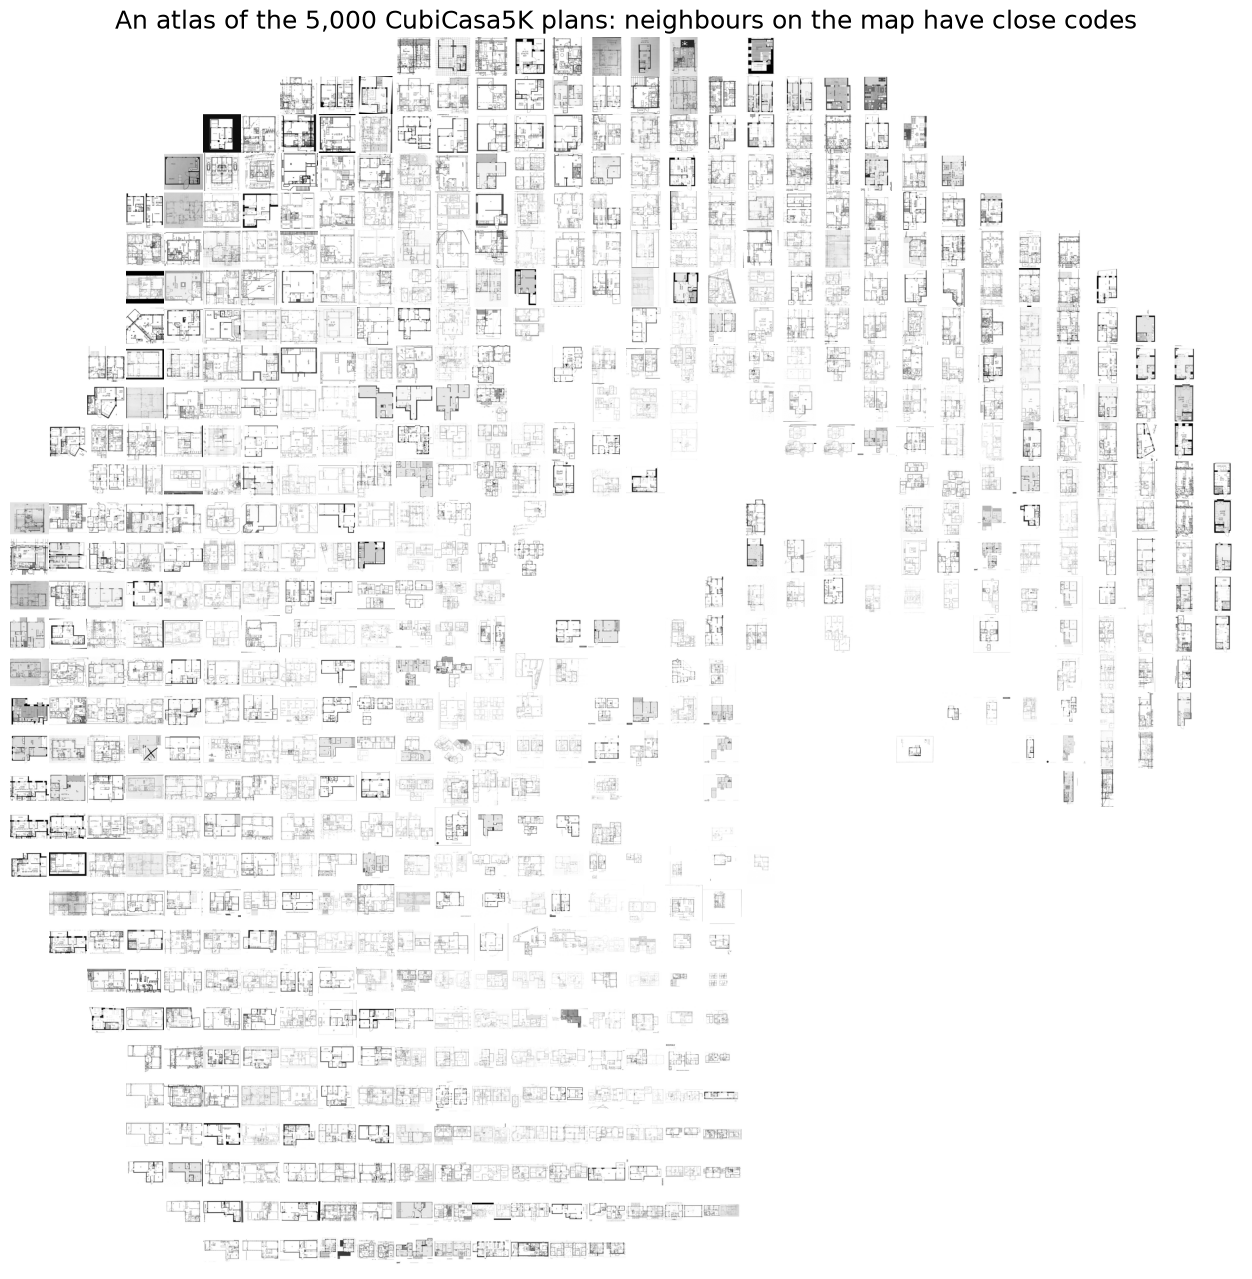

In [27]:
#the 5,000 codes on a 2D map (UMAP, as on Day 3), scaled to 0-1 so we can cut it into a grid
atlas_xy = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=RANDOM_STATE).fit_transform(codes_all.numpy())
atlas_xy = (atlas_xy - atlas_xy.min(axis=0)) / (atlas_xy.max(axis=0) - atlas_xy.min(axis=0))

GRID = 32   #32 x 32 cells; every cell that has plans shows the one closest to its centre
fig, ax = plt.subplots(figsize=(16, 16))
for row in range(GRID):
    for col in range(GRID):
        centre = np.array([(col + 0.5) / GRID, (row + 0.5) / GRID])
        distances = np.linalg.norm(atlas_xy - centre, axis=1)
        nearest = distances.argmin()
        if distances[nearest] < 0.7 / GRID:
            plan = 1 - X_all[nearest, 0].numpy()   #dark lines on white, like a printed plan
            ax.imshow(plan, cmap="gray", vmin=0, vmax=1,
                      extent=(col / GRID, (col + 1) / GRID, row / GRID, (row + 1) / GRID))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")
ax.set_title("An atlas of the 5,000 CubiCasa5K plans: neighbours on the map have close codes", fontsize=18)
save_fig("08_plan_atlas")
plt.show()

### Interpretation of the plan atlas

The atlas projects the collection's 128-number codes into two
dimensions using UMAP, then displays representative plans on a grid.

Wide drawings appear mainly toward the left and bottom, while
tall, narrow drawings appear toward the right. Faint drawings
are common in the central region.

This suggests that proportions and drawing appearance influence
the representation. It does not establish grouping by bedroom
count, room function or circulation.

The map uses all 5,000 codes but shows selected thumbnails.
UMAP approximates neighbourhoods; the actual search uses
Euclidean distances in the full latent space.

# 5. Saving the model for Tuesday's server
Like section 9 of the class notebook. For similarity search the server needs more than the model: it also needs the codes of the whole collection, to compare a new plan with.

| File | What's in it |
|---|---|
| `floorplan_ae.onnx` | the model, with two outputs: the code (for the search) and the reconstruction |
| `floorplan_ae_config.json` | the image size, the preprocessing steps, the code size and the setup |
| `collection_codes.npy` | the code of each of the 5,000 plans |
| `collection_ids.json` | which plan each code belongs to |
| `examples/*.png` | four plans to try on the server page |

The `.onnx`, `.pt` and `.npy` files go to Hugging Face, not to GitHub (they're in `.gitignore`).

In [28]:
class CodeAndReconstruction(nn.Module):
    # Wraps the AE so the ONNX file returns both the code and the reconstruction
    def __init__(self, ae):
        super().__init__()
        self.ae = ae

    def forward(self, x):
        code = self.ae.encoder(x)
        return code, self.ae.decoder(code)


import logging

#the ONNX exporter warns that torchvision isn't installed: we don't need it
logging.getLogger("torch.onnx").setLevel(logging.ERROR)

best = best.cpu().eval()
export_model = CodeAndReconstruction(best).eval()
torch.save(best.state_dict(), MODEL_DIR / "floorplan_ae.pt")
torch.onnx.export(export_model, (X_test[:1],), MODEL_APP_DIR / "floorplan_ae.onnx",
                  input_names=["image"], output_names=["code", "reconstruction"],
                  dynamic_shapes={"x": {0: torch.export.Dim("batch")}}, external_data=False, verbose=False)

np.save(MODEL_APP_DIR / "collection_codes.npy", encode(best, X_all).numpy().astype(np.float32))
(MODEL_APP_DIR / "collection_ids.json").write_text(json.dumps(plan_ids.tolist()))

config = {
    "architecture": best_name,
    "latent_dim": int(codes_all.shape[1]),
    "image_size": IMAGE_SIZE,
    "preprocessing": "greyscale, invert (walls bright, background dark), pad to a square with black, "
                     "resize to 128x128 (Lanczos), pixels scaled to 0-1",
    "similarity": "Euclidean distance between codes; smaller = more similar",
    "collection": "CubiCasa5K, all 5,000 plans (train + validation + test)",
    "test_retrieval_top1": round(float(retrieval_top1(best, X_test)), 3),
    "notebook_revision": "3_integrated_batchnorm",
    "batch_normalization": bool(getattr(best, "batch_norm", False)),
    "selection": "main setup selected by validation retrieval; MSE breaks ties",
    "initialization": "PyTorch defaults for main setups; explicit initialization only in ablation",
}
(MODEL_APP_DIR / "floorplan_ae_config.json").write_text(json.dumps(config, indent=2))

for q in [0, 50, 120, 250]:
    plt.imsave(MODEL_APP_DIR / "examples" / f"plan_{ids_test[q].replace('/', '_')}.png",
               1 - X_test[q].squeeze().numpy(), cmap="gray", vmin=0, vmax=1)

for path in sorted(MODEL_APP_DIR.rglob("*.*")):
    print(f"{str(path):55s} {path.stat().st_size / 1024:9.1f} KB")

..\model_app_bn_architecture\collection_codes.npy          2500.1 KB
..\model_app_bn_architecture\collection_ids.json            154.2 KB
..\model_app_bn_architecture\examples\plan_high_quality_architectural_1191.png      11.1 KB
..\model_app_bn_architecture\examples\plan_high_quality_architectural_1966.png       9.0 KB
..\model_app_bn_architecture\examples\plan_high_quality_architectural_20022.png       9.2 KB
..\model_app_bn_architecture\examples\plan_high_quality_architectural_435.png       7.4 KB
..\model_app_bn_architecture\floorplan_ae.onnx             4617.5 KB
..\model_app_bn_architecture\floorplan_ae_config.json         0.7 KB


In [29]:
# Check: ONNX Runtime gives the same codes and the same errors as PyTorch
import onnxruntime as ort

session = ort.InferenceSession(MODEL_APP_DIR / "floorplan_ae.onnx")
batch = X_test[:5].numpy()
onnx_code, onnx_rec = session.run(None, {"image": batch})
onnx_scores = ((onnx_rec - batch) ** 2).mean(axis=(1, 2, 3))

with torch.no_grad():
    torch_code, torch_rec = export_model(X_test[:5])
torch_scores = ((torch_rec - X_test[:5]) ** 2).mean(dim=(1, 2, 3)).numpy()

print("PyTorch errors:     ", torch_scores.round(5))
print("ONNX Runtime errors:", onnx_scores.round(5))
print("same errors:", np.allclose(torch_scores, onnx_scores, atol=1e-6))
print("same codes: ", np.allclose(torch_code.numpy(), onnx_code, atol=1e-4))
assert np.allclose(torch_scores, onnx_scores, atol=1e-6), "ONNX reconstruction scores differ"
assert np.allclose(torch_code.numpy(), onnx_code, atol=1e-4), "ONNX codes differ"


PyTorch errors:      [0.00745 0.00455 0.00447 0.01864 0.00258]
ONNX Runtime errors: [0.00745 0.00455 0.00447 0.01864 0.00258]
same errors: True
same codes:  True


### ONNX export verification

The exported batch-normalized model was checked against PyTorch
using five test images.

Latent codes matched within an absolute tolerance of 0.0001.
Per-image reconstruction MSE values matched within an absolute
tolerance of 0.000001.

These checks support numerical agreement for the tested batch.
They do not measure retrieval quality or verify server deployment.

In [30]:
#one folder for Hugging Face: the model card (models/README.md) and everything it needs
import shutil

for name in ["floorplan_ae.onnx", "floorplan_ae_config.json", "collection_codes.npy", "collection_ids.json"]:
    shutil.copy(MODEL_APP_DIR / name, MODEL_DIR / name)
shutil.copytree(MODEL_APP_DIR / "examples", MODEL_DIR / "examples", dirs_exist_ok=True)

(MODEL_DIR / "figures").mkdir(exist_ok=True)
for name in ["02_training_curves.png", "03_reconstructions.png", "04_similarity_search.png",
             "05_baselines.png", "06_failures_by_ink.png", "08_plan_atlas.png"]:
    shutil.copy(FIG_DIR / name, MODEL_DIR / "figures" / name)

for path in sorted(MODEL_DIR.rglob("*.*")):
    print(f"{str(path):55s} {path.stat().st_size / 1024:9.1f} KB")

..\models_bn_architecture\collection_codes.npy             2500.1 KB
..\models_bn_architecture\collection_ids.json               154.2 KB
..\models_bn_architecture\examples\plan_high_quality_architectural_1191.png      11.1 KB
..\models_bn_architecture\examples\plan_high_quality_architectural_1966.png       9.0 KB
..\models_bn_architecture\examples\plan_high_quality_architectural_20022.png       9.2 KB
..\models_bn_architecture\examples\plan_high_quality_architectural_435.png       7.4 KB
..\models_bn_architecture\figures\02_training_curves.png      96.5 KB
..\models_bn_architecture\figures\03_reconstructions.png     492.4 KB
..\models_bn_architecture\figures\04_similarity_search.png     563.1 KB
..\models_bn_architecture\figures\05_baselines.png           34.1 KB
..\models_bn_architecture\figures\06_failures_by_ink.png      37.8 KB
..\models_bn_architecture\figures\08_plan_atlas.png        1308.9 KB
..\models_bn_architecture\floorplan_ae.onnx                4617.5 KB
..\models_bn_arch

# 6. Version 2: compare the layout, not the drawing style

The atlas and the failures say the same thing: after the proportions, the second thing our codes follow is **how a plan is drawn**: thick or thin lines, grey fills, faint scans. For an architect that's the wrong kind of similarity. A plan should find plans with a similar layout, whatever pen drew them.

Chloe's notebook gave us the tools to measure this. She described every plan with four rendering features (how much is drawn, contrast, edge strength and sharpness) and measured the error only on the drawn pixels. We use her features to check how much drawing style is in our codes, then try to take it out by cleaning every plan before the model sees it.

### How much style is in the v1 codes?
For each feature we compare a plan with its 5 nearest plans and with 5 random plans. 100% means the neighbours are as different as random plans, so the search ignores that feature. A low value means the neighbours are alike in that feature, so the search follows it.

In [31]:
#Chloe's rendering features, measured on every plan as it is drawn (walls bright, 0-1)
def style_features(X):
    x = X[:, 0].numpy()
    dx = np.abs(np.diff(x, axis=2)).mean(axis=(1, 2))
    dy = np.abs(np.diff(x, axis=1)).mean(axis=(1, 2))
    laplacian = x[:, 1:-1, :-2] + x[:, 1:-1, 2:] + x[:, :-2, 1:-1] + x[:, 2:, 1:-1] - 4 * x[:, 1:-1, 1:-1]
    return pd.DataFrame({
        "how much is drawn": (x > 0.1).mean(axis=(1, 2)),
        "contrast": x.std(axis=(1, 2)),
        "edge strength": (dx + dy) / 2,
        "sharpness": laplacian.var(axis=(1, 2)),
        "grey fills": ((x > 0.15) & (x < 0.6)).mean(axis=(1, 2)),
    })


def style_in_codes(codes, features, k=5):
    #for each feature: how different are a plan and its 5 nearest plans, compared with 5 random plans?
    #100% = the neighbours are as different as random plans (the code ignores it), 0% = identical
    neighbours = torch.cdist(codes, codes).topk(k + 1, largest=False).indices[:, 1:].numpy()
    random_plans = np.random.default_rng(RANDOM_STATE).integers(0, len(codes), (len(codes), k))
    ratios = {}
    for name in features.columns:
        v = features[name].to_numpy()
        ratios[name] = np.abs(v[:, None] - v[neighbours]).mean() / np.abs(v[:, None] - v[random_plans]).mean()
    return pd.Series(ratios)


features_all = style_features(X_all)
style_v1 = style_in_codes(codes_all, features_all)
style_v1.to_frame("neighbours vs random (v1)").style.format("{:.0%}")

,neighbours vs random (v1)
how much is drawn,84%
contrast,78%
edge strength,75%
sharpness,82%
grey fills,82%


### Drawing appearance in the retrieved neighbours

Nearest neighbours have smaller average differences in the measured
drawing features than random pairs.

Their differences are 84% of random-pair differences for drawing
density, 78% for contrast, 75% for edge strength, and 82% for both
sharpness and grey fills.

This indicates that retrieved plans also share aspects of drawing
appearance. It does not establish whether appearance causes the
matches, because these features may correlate with plan geometry.

These values are feature-difference ratios, not accuracy scores.
We next test whether cleaning the drawings changes these ratios
and retrieval performance.

### Cleaning the drawings
Every plan is reduced to its lines, the same way for every drawing:
1. a minimum and then a maximum filter of 5 x 5 px (an "opening") erase every line thinner than about 5 px and keep only the wide parts: grey fills, grey paper, dark borders;
2. the plan minus these wide parts leaves only the lines;
3. the lines of each plan are scaled by its own strong lines (90th percentile) and cut at 0.35, so a faint scan and a bold drawing come out equally bright.

The server has to do exactly the same to every upload.

share of line pixels: 0.066 as drawn, 0.119 cleaned
how much the plans differ in amount drawn (std / mean): 0.56 as drawn, 0.38 cleaned
Figure saved to ..\figures_bn_architecture\09_cleaning.png


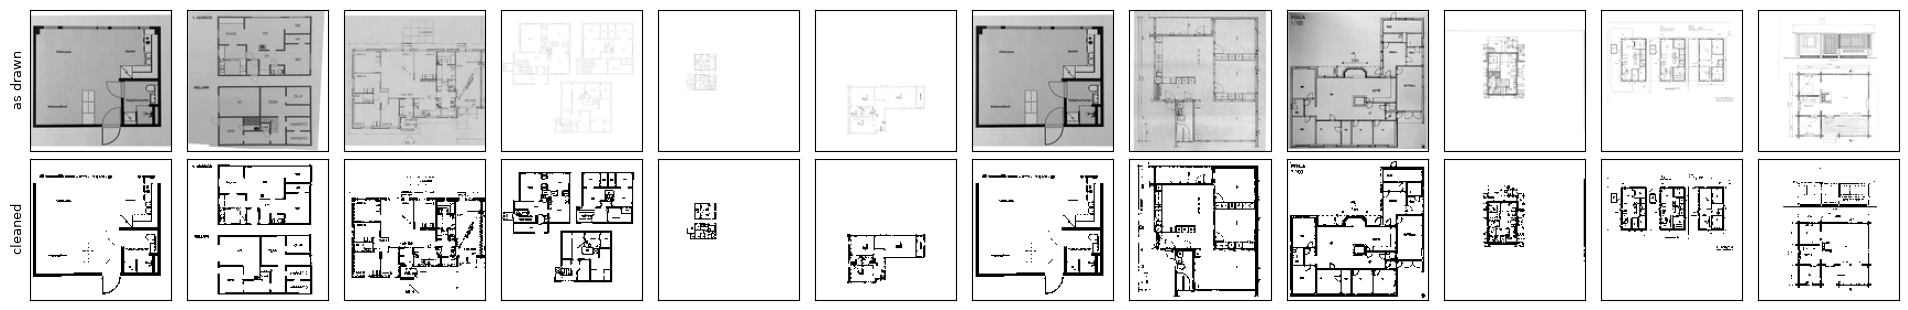

In [32]:
def clean_plan(plan):
    #plan: 128x128 uint8, walls bright. Keep only the lines, the same way for every drawing
    image = Image.fromarray(plan)
    wide = image.filter(ImageFilter.MinFilter(5)).filter(ImageFilter.MaxFilter(5))   #only what is wider than ~4 px: fills, grey paper, dark borders
    lines = np.asarray(image, np.float32) - np.asarray(wide, np.float32)             #the plan minus the wide parts = the lines
    strong = lines[lines > 8]
    if strong.size < 20:                                                             #nothing drawn
        return np.zeros_like(plan)
    return ((lines / np.percentile(strong, 90)) > 0.35).astype(np.uint8) * 255      #scaled by its own lines: faint and bold come out the same


from PIL import ImageFilter

cleaned = np.stack([clean_plan(plan) for plan in images])
X2_all = torch.from_numpy(cleaned).float().div(255).unsqueeze(1)
X2_train = X2_all[plan_splits == "train"]
X2_val = X2_all[plan_splits == "val"]
X2_test = X2_all[plan_splits == "test"]
print(f"share of line pixels: {X_all.mean():.3f} as drawn, {X2_all.mean():.3f} cleaned")
print(f"how much the plans differ in amount drawn (std / mean): {X_all.mean(dim=(1, 2, 3)).std() / X_all.mean():.2f} as drawn, "
      f"{X2_all.mean(dim=(1, 2, 3)).std() / X2_all.mean():.2f} cleaned")

#the plans with the most grey fill, the faintest, the boldest, and the first three
grey_order = features_all["grey fills"].to_numpy().argsort()
ink_order = features_all["how much is drawn"].to_numpy().argsort()
picks = list(grey_order[-3:]) + list(ink_order[:3]) + list(ink_order[-3:]) + [0, 1, 2]
show_images([X_all[picks], X2_all[picks]], row_labels=["as drawn", "cleaned"])
save_fig("09_cleaning")
plt.show()

### Effect of cleaning the drawings

Cleaning removes many grey backgrounds and fills while making
faint lines more visible. The resulting images have a more
consistent black-and-white appearance.

Average inverted pixel intensity increases from 0.066 to 0.119
because retained lines become fully bright in the model input.
Relative variation across plans decreases from 0.56 to 0.38.

However, cleaning also removes or fragments some boundaries,
including parts of thick walls. It is therefore a trade-off
between appearance standardization and information preservation.

We must evaluate retrieval after training on the cleaned images;
a cleaner appearance alone does not establish better search.

### Training the integrated-BN architecture on cleaned plans

Train ConvAE(code 128, BN enabled) with the same training settings. For the closest controlled input comparison, compare against setup C on the original inputs, not a different validation-selected architecture.


In [33]:
torch.manual_seed(RANDOM_STATE)
#setup C again (conv, code 128), same split, seed, epochs and loss: only the input changes
model_v2, history_v2, time_v2 = train_autoencoder(ConvAE(latent_dim=128), X2_train, X2_val, epochs=EPOCHS, verbose=False)


def retrieval_cleaned(model, X_test_drawn, X_test_cleaned):
    #the shifted, noisy copy is made from the plan AS DRAWN and then cleaned, like an upload on the server
    shifted = perturb(X_test_drawn)
    shifted_cleaned = np.stack([clean_plan((s[0].numpy() * 255).round().astype(np.uint8)) for s in shifted])
    query_codes = encode(model, torch.from_numpy(shifted_cleaned).float().div(255).unsqueeze(1))
    return (torch.cdist(query_codes, encode(model, X_test_cleaned)).argmin(dim=1) == torch.arange(len(X_test_cleaned))).numpy()


def foreground_mse(model, X):
    #Chloe's idea: the error on the drawn pixels only, where a blank page can't cheat
    error = (reconstruct(model, X) - X) ** 2
    return error[X > 0.5].mean().item()


found_v2 = retrieval_cleaned(model_v2, X_test, X2_test)
version_table = pd.DataFrame({
    "input": ["plans as drawn", "cleaned plans"],
    "test MSE": [reconstruction_error(best, X_test).mean().item(), reconstruction_error(model_v2, X2_test).mean().item()],
    "blank page MSE": [(X_test ** 2).mean().item(), (X2_test ** 2).mean().item()],
    "foreground MSE": [foreground_mse(best, X_test), foreground_mse(model_v2, X2_test)],
    "retrieval top-1 (test)": [found.mean(), found_v2.mean()],
}, index=["v1 (Monday)", "v2"])

#and by how much is drawn, like in section 4
by_ink_v2 = pd.Series(found_v2).groupby(ink_quarter, observed=True).mean()
print(pd.DataFrame({"v1": by_ink, "v2": by_ink_v2}).map("{:.0%}".format))
version_table

trained in 192 s
              v1   v2
least drawn  51%  89%
2nd quarter  44%  99%
3rd quarter  53%  90%
most drawn   69%  82%


,input,test MSE,blank page MSE,foreground MSE,retrieval top-1 (test)
v1 (Monday),plans as drawn,0.0118,0.0300,0.1778,0.5425
v2,cleaned plans,0.0671,0.1137,0.4234,0.9000


### Retrieval after training on cleaned drawings

The cleaned-input pipeline achieved 90% test top-1 original
recovery, compared with 54.25% for the as-drawn pipeline:
an increase of 35.75 percentage points.

Recovery improved in all four drawing-intensity groups.
The largest increase occurred in the second quarter,
from 44% to 99%.

The cleaned model's reconstruction MSE was 0.0671, compared
with its blank-page baseline of 0.1137. Absolute MSE values
should not be compared directly with the as-drawn model
because the reconstruction targets differ.

This experiment evaluates the full pipeline: perturbed queries
are cleaned before encoding. It demonstrates improved recovery
of the same drawing under the tested shift and noise, not
architectural relevance between different homes.

### Is there less style in the v2 codes?

Figure saved to ..\figures_bn_architecture\10_style_in_codes.png


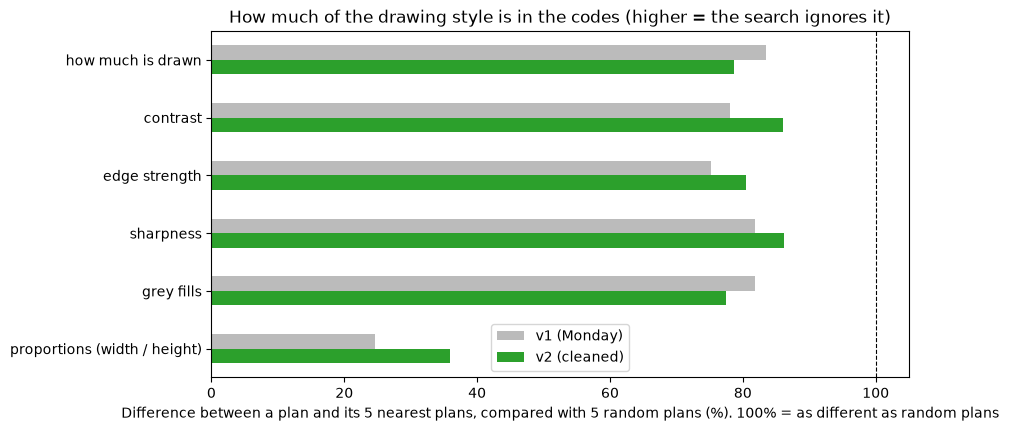

,v1 (Monday),v2 (cleaned)
how much is drawn,84%,79%
contrast,78%,86%
edge strength,75%,80%
sharpness,82%,86%
grey fills,82%,77%
proportions (width / height),25%,36%


In [34]:
codes_v2_all = encode(model_v2, X2_all)
features_all["proportions (width / height)"] = np.log((X2_all[:, 0] > 0.5).any(dim=1).sum(dim=1).clamp(min=1).numpy()
                                                      / (X2_all[:, 0] > 0.5).any(dim=2).sum(dim=1).clamp(min=1).numpy())
style_table = pd.DataFrame({"v1 (Monday)": style_in_codes(codes_all, features_all),
                            "v2 (cleaned)": style_in_codes(codes_v2_all, features_all)})

ax = (style_table * 100).plot.barh(figsize=(9, 4.5), color=["#bbbbbb", "#2ca02c"])
ax.axvline(100, color="black", lw=0.8, ls="--")
ax.invert_yaxis()
ax.set_xlabel("Difference between a plan and its 5 nearest plans, compared with 5 random plans (%). 100% = as different as random plans")
ax.set_title("How much of the drawing style is in the codes (higher = the search ignores it)")
save_fig("10_style_in_codes")
plt.show()
style_table.style.format("{:.0%}")

### Drawing characteristics after cleaning

Cleaning produced mixed changes in neighbour appearance.

Contrast, edge-strength and sharpness ratios moved closer to
100%, meaning neighbours became less similar in these measured
features relative to random pairs. However, drawing-density
and grey-fill ratios decreased, indicating greater similarity
in those features.

The proportions ratio increased from 25% to 36%, although
neighbours still shared proportions much more than random pairs.

These ratios describe characteristics of retrieved neighbours;
they do not directly measure information stored in the codes
or prove that the model ignores drawing style.

Despite the improvement in shifted-copy recovery to 90%,
architectural relevance remains to be evaluated separately.

### The same four searches with v2

query 0: distances 33.02-36.07
query 50: distances 45.59-47.30
query 120: distances 35.14-37.44
query 250: distances 31.69-34.19
Figure saved to ..\figures_bn_architecture\11_similarity_search_v2.png


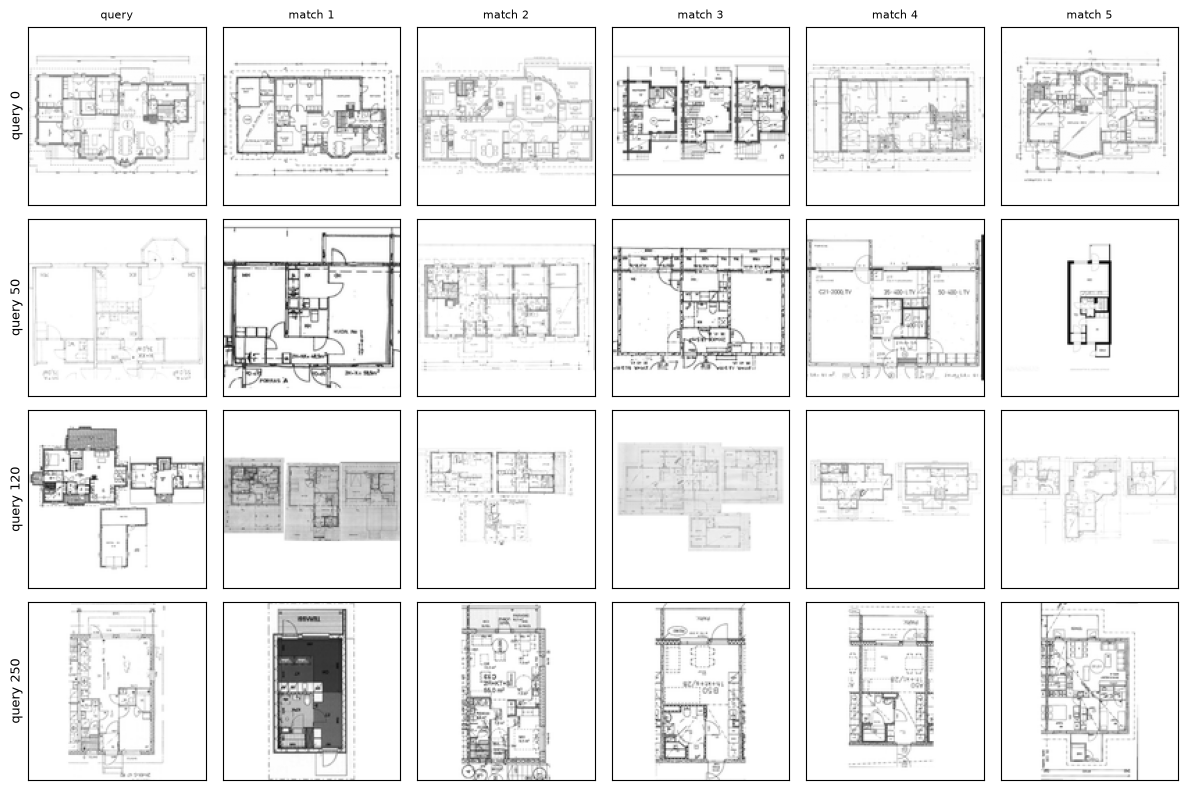

In [35]:
#the same four queries as in section 4, now with v2. We show the plans as drawn, so the style is visible
rows, labels = [], []
for q in [0, 50, 120, 250]:
    query_index = test_positions[q]
    idx, dists = most_similar(codes_v2_all[query_index], codes_v2_all, exclude=query_index)
    rows.append(torch.cat([X_all[query_index:query_index + 1], X_all[idx]]))
    labels.append(f"query {q}")
    print(f"query {q}: distances {dists.min():.2f}-{dists.max():.2f}")

show_images(rows, row_labels=labels, titles=["query"] + [f"match {i}" for i in range(1, 6)], size=2.0)
save_fig("11_similarity_search_v2")
plt.show()

### Similarity search after cleaning

The cleaned-input model retrieves plans across different drawing
appearances. For example, the faint query 50 returns several bold
drawings, while query 250 returns narrow plans with varied contrast
and fills.

Broad proportions and page composition remain influential.
Several matches to query 120 also contain multiple drawings or
volumes. Internal room arrangements still differ across results,
and some matches remain weak architectural precedents.

These examples suggest some tolerance to differences in rendering.
They do not establish improved architectural relevance. The 90%
original-recovery result measures a separate shifted-and-noisy-copy
benchmark.

Distances are specific to this encoder and should not be compared
directly with distances from the as-drawn model.

### The atlas with v2

Figure saved to ..\figures_bn_architecture\12_plan_atlas_v2.png


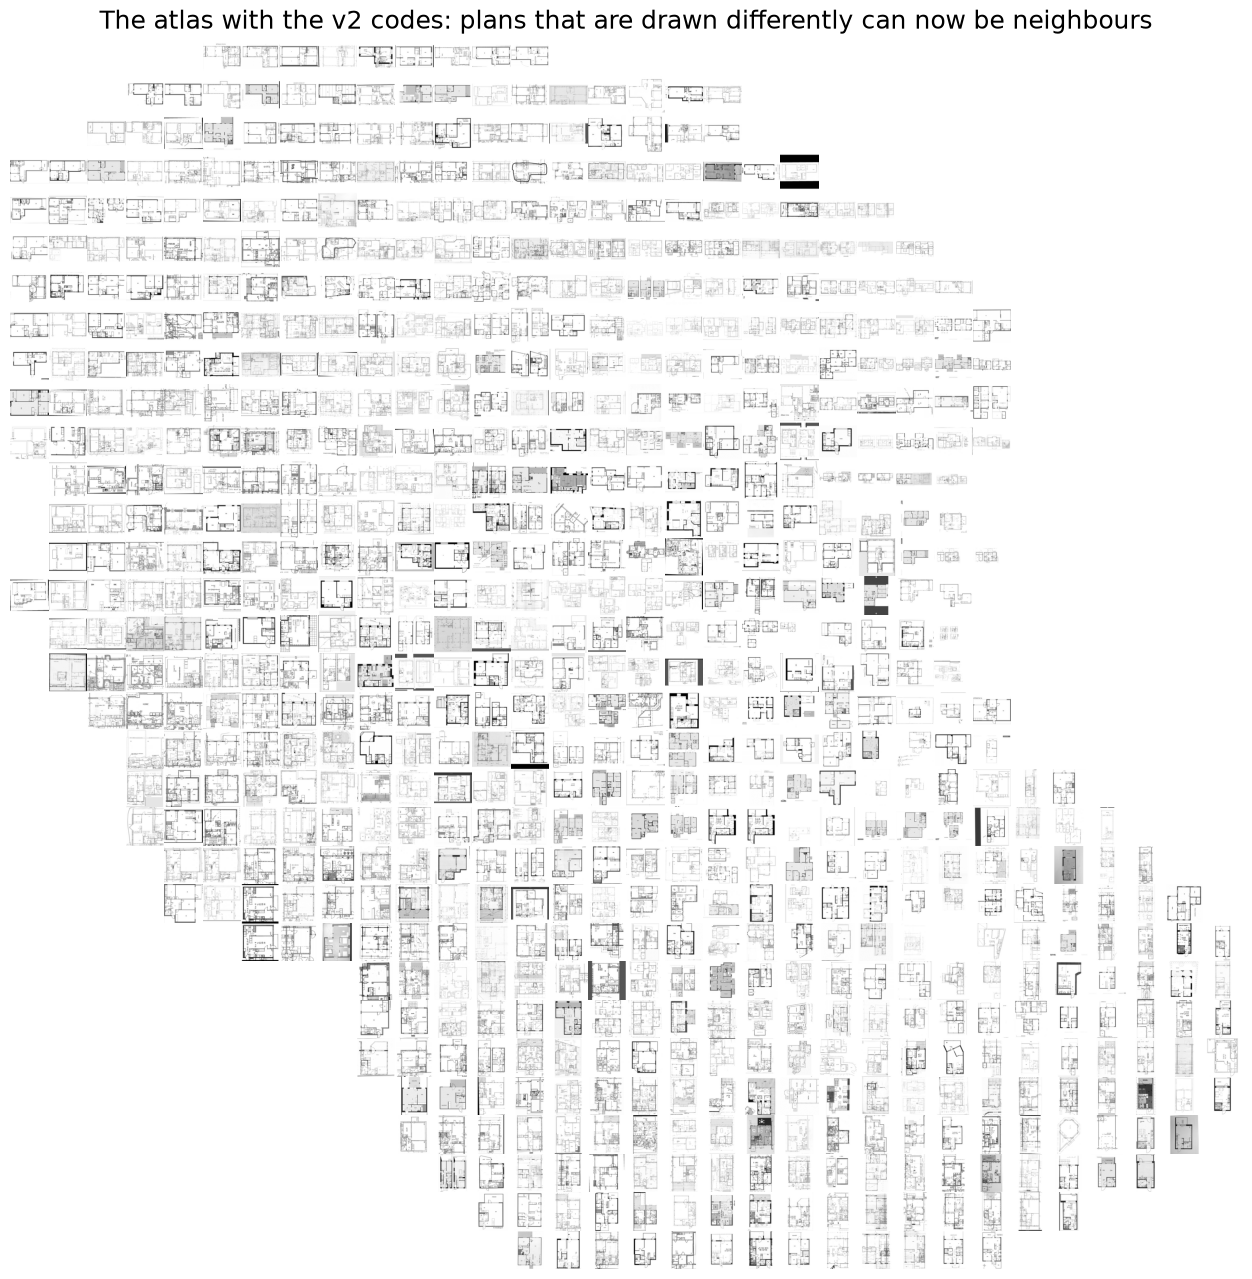

In [36]:
#the atlas again, with the v2 codes, drawn with the plans as they are drawn
atlas_v2_xy = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=RANDOM_STATE).fit_transform(codes_v2_all.numpy())
atlas_v2_xy = (atlas_v2_xy - atlas_v2_xy.min(axis=0)) / (atlas_v2_xy.max(axis=0) - atlas_v2_xy.min(axis=0))

fig, ax = plt.subplots(figsize=(16, 16))
for row in range(GRID):
    for col in range(GRID):
        centre = np.array([(col + 0.5) / GRID, (row + 0.5) / GRID])
        distances = np.linalg.norm(atlas_v2_xy - centre, axis=1)
        nearest = distances.argmin()
        if distances[nearest] < 0.7 / GRID:
            ax.imshow(1 - X_all[nearest, 0].numpy(), cmap="gray", vmin=0, vmax=1,
                      extent=(col / GRID, (col + 1) / GRID, row / GRID, (row + 1) / GRID))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")
ax.set_title("The atlas with the v2 codes: plans that are drawn differently can now be neighbours", fontsize=18)
save_fig("12_plan_atlas_v2")
plt.show()

### Atlas after training on cleaned drawings

The atlas shows representative original drawings positioned using
the cleaned-input model's codes.

Wide drawings appear mainly toward the top, while tall drawings
appear toward the bottom. Drawings with different contrast and
fills coexist in several regions.

This suggests that proportions remain influential and that some
neighbourhoods mix drawing appearances. However, the atlas does
not prove that drawing style has been removed or that plans share
room functions or circulation.

UMAP only approximates neighbourhood relationships. Its orientation
is arbitrary, so locations should not be compared directly with
the previous atlas. The grid displays selected representatives,
not all 5,000 plans.

### Saving v2 for the server
v2 is saved next to v1 with new names (`floorplan_ae_v2.onnx`, `floorplan_ae_v2_config.json`, `collection_codes_v2.npy`), so Monday's files stay as they were. We also keep the map positions of the v2 atlas (`atlas_v2_xy.npy`) for the app.

In [37]:
#v2 for the server: the same two outputs (code and reconstruction), new file names so v1 stays as it was
model_v2 = model_v2.cpu().eval()
torch.save(model_v2.state_dict(), MODEL_DIR / "floorplan_ae_v2.pt")
torch.onnx.export(CodeAndReconstruction(model_v2).eval(), (X2_test[:1],), MODEL_APP_DIR / "floorplan_ae_v2.onnx",
                  input_names=["image"], output_names=["code", "reconstruction"],
                  dynamic_shapes={"x": {0: torch.export.Dim("batch")}}, external_data=False, verbose=False)
np.save(MODEL_APP_DIR / "collection_codes_v2.npy", codes_v2_all.numpy().astype(np.float32))
np.save(MODEL_APP_DIR / "atlas_v2_xy.npy", atlas_v2_xy.astype(np.float32))   #the map positions, for the app

config_v2 = dict(config, batch_normalization=True, latent_dim=128, architecture="C (conv, code 128), with integrated BN, trained on cleaned plans",
                 preprocessing=config["preprocessing"] + "; then cleaned: keep only lines thinner than 5 px "
                               "(plan minus its 5x5 opening), scale by the 90th percentile of its lines, threshold 0.35",
                 test_retrieval_top1=round(float(found_v2.mean()), 3))
(MODEL_APP_DIR / "floorplan_ae_v2_config.json").write_text(json.dumps(config_v2, indent=2))

#check the ONNX file like for v1
session_v2 = ort.InferenceSession(MODEL_APP_DIR / "floorplan_ae_v2.onnx")
onnx_code, _ = session_v2.run(None, {"image": X2_test[:5].numpy()})
print("same codes as PyTorch:", np.allclose(encode(model_v2, X2_test[:5]).numpy(), onnx_code, atol=1e-4))

for name in ["floorplan_ae_v2.onnx", "floorplan_ae_v2_config.json", "collection_codes_v2.npy", "atlas_v2_xy.npy"]:
    shutil.copy(MODEL_APP_DIR / name, MODEL_DIR / name)
for name in ["09_cleaning.png", "10_style_in_codes.png", "11_similarity_search_v2.png", "12_plan_atlas_v2.png"]:
    shutil.copy(FIG_DIR / name, MODEL_DIR / "figures" / name)
print("v2 saved in", MODEL_APP_DIR, "and", MODEL_DIR)

same codes as PyTorch: True
v2 saved in ..\model_app_bn_architecture and ..\models_bn_architecture


# 7. Conclusions and limitations

### Architecture

We integrated batch normalization directly into the convolutional
autoencoder: four encoder layers and three hidden decoder layers.
The latent code and final sigmoid output are not normalized.

Among the main setups, validation selected setup C, with a
128-number code.

### Reconstruction and retrieval

The as-drawn batch-normalized model achieved test MSE 0.0118:
approximately 61% below a blank-page baseline and 51% below
the average-training-image baseline.

In the controlled four-way experiment, combining batch normalization
and explicit initialization achieved the lowest validation MSE
(0.0104). However, the no-BN control achieved the highest validation
retrieval (73.75%, versus 65.50% for both changes).

Better reconstruction therefore did not guarantee better retrieval.

### Effect of cleaning

Training the batch-normalized model on cleaned drawings increased
test original recovery from 54.25% to 90%. Recovery improved in
all four drawing-intensity groups.

This compares complete preprocessing-and-model pipelines.
The reconstruction targets differ, so their absolute MSE values
are not directly comparable.

Changes in drawing-style similarity were mixed. Cleaning did not
remove all influence of drawing appearance.

### Export verification

The as-drawn ONNX model matched PyTorch codes and reconstruction
scores on the checked batch. The cleaned ONNX model also matched
PyTorch codes on its checked batch.

Artifacts were saved in model_app_bn_architecture and
models_bn_architecture. The existing server was not updated.

### Limitations and next steps

- The 90% result measures recovery of shifted and noisy copies,
  not relevance between different homes.
- At 128 × 128 pixels, thin walls, doors, furniture and text
  remain blurred or missing.
- Cleaning can remove useful boundaries and details.
- Retrieved plans often share proportions and page composition;
  room function and circulation have not been validated.
- Results use one training seed.
- Test results have been inspected during development; further
  tuning needs validation data, with a fresh final evaluation
  for stronger generalization claims.

The next step is to evaluate architectural relevance using room
annotations and human review, rather than original recovery alone.